## Setup and Imports for Visualization

In [20]:
import sys
import os
import matplotlib.pyplot as plt
from river import tree, metrics, drift, utils

sys.path.append(os.path.abspath('../src'))
from data_loader import load_adanen_stream, stream_generator

# Set global plot style
plt.rcParams.update({'font.size': 12, 'figure.figsize': (12, 6)})

## Prequential Evaluation Engine

In [21]:
def track_prequential_accuracy(file_path, detector, window_size=500):
    stream = load_adanen_stream(file_path)
    model = tree.HoeffdingTreeClassifier()
    metric = utils.Rolling(metrics.Accuracy, window_size=window_size)

    acc_history = []
    drift_points = []

    for i, (x, y) in enumerate(stream_generator(stream)):
        y_pred = model.predict_one(x)
        model.learn_one(x, y)

        if y_pred is not None:
            metric.update(y, y_pred)
            # show accuracy only when the rolling window is full
            acc_history.append(metric.get() * 100 if i >= window_size else float('nan'))

            error = 0 if y_pred == y else 1
            detector.update(error)

            if detector.drift_detected:
                drift_points.append(i)
                model = tree.HoeffdingTreeClassifier()  # active adaptation
        else:
            acc_history.append(float('nan') if not acc_history else acc_history[-1])

    return acc_history, drift_points

## Plotting Helper

In [22]:
# True drift positions
TRUE_DRIFTS = list(range(4000, 11501, 500))

def plot_drift_result(acc_history, detected, title, color, save_path):
    plt.figure()
    plt.plot(acc_history, label='Prequential Accuracy (Window=500)', color=color, linewidth=1.5)

    # orange lines true drifts
    for t in TRUE_DRIFTS:
        plt.axvline(x=t, color='orange', linestyle=':', alpha=0.7,
                    label='True Drift' if t == TRUE_DRIFTS[0] else "")

    # red lines drifts detected by DDM (model resets)
    for d in detected:
        plt.axvline(x=d, color='red', linestyle='--', alpha=0.8,
                    label='Detected Drift (DDM)' if d == detected[0] else "")

    plt.title(title)
    plt.xlabel('Number of Instances Processed')
    plt.ylabel('Accuracy (%)')
    plt.ylim(40, 100)
    plt.legend(loc='lower right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()
    print(f"Total drifts detected by DDM: {len(detected)}")

## Visualize Abrupt Concept Drift (DDM)

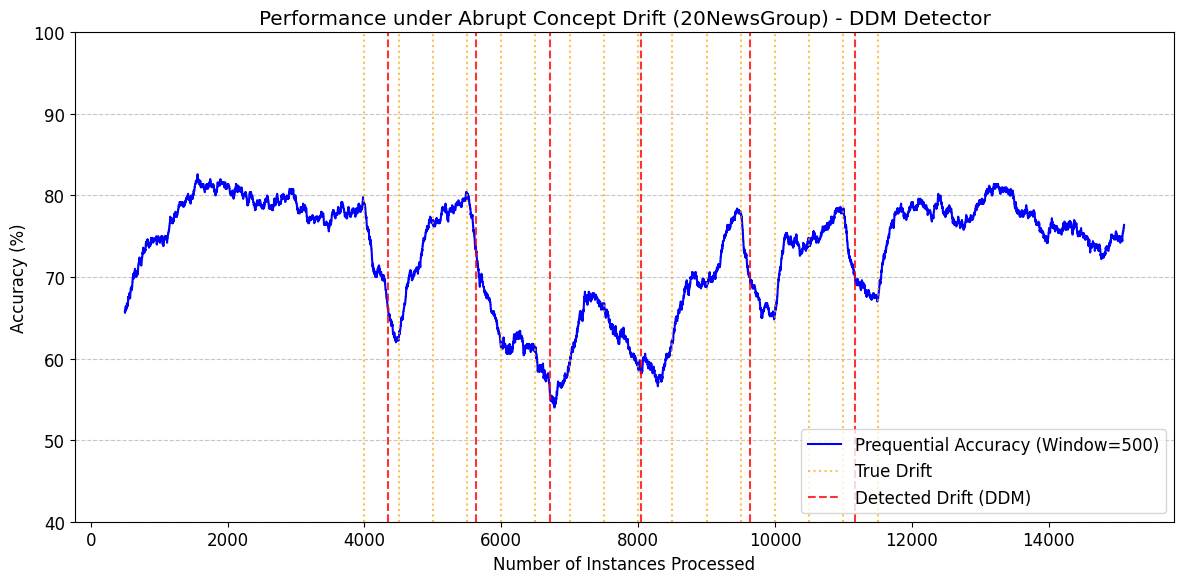

Total drifts detected by DDM: 6


In [23]:
file_path_abrupt = '../data/adanen_streams/20ng_abrupt.data'
detector_abrupt = drift.binary.DDM()

acc_history_abr, drifts_abr = track_prequential_accuracy(file_path_abrupt, detector_abrupt)

plot_drift_result(acc_history_abr, drifts_abr,
                  'Performance under Abrupt Concept Drift (20NewsGroup) - DDM Detector',
                  'blue', '../images/20ng_abrupt_drift.png')

### Results: Abrupt Drift

- DDM detected 6 drifts, at about 4350, 5650, 6700, 8050, 9600 and 11200 instances.
- The data has about 16 true drifts (orange dotted lines), so DDM reacts only to a part of them.
- The accuracy grows quickly and reaches about 80% around 2000 instances. It stays at about 78-80% until the first drift.
- After the drifts the accuracy drops. The lowest point is about 55% near 6800 instances.
- After each reset the model learns the new data and the accuracy goes back up to about 75-80%.
- The first detection (about 4350) comes after the first true drift at 4000, so DDM reacts with a delay of about 350 instances.
- At the end the accuracy is about 75%.

## Visualize Gradual Concept Drift (DDM)

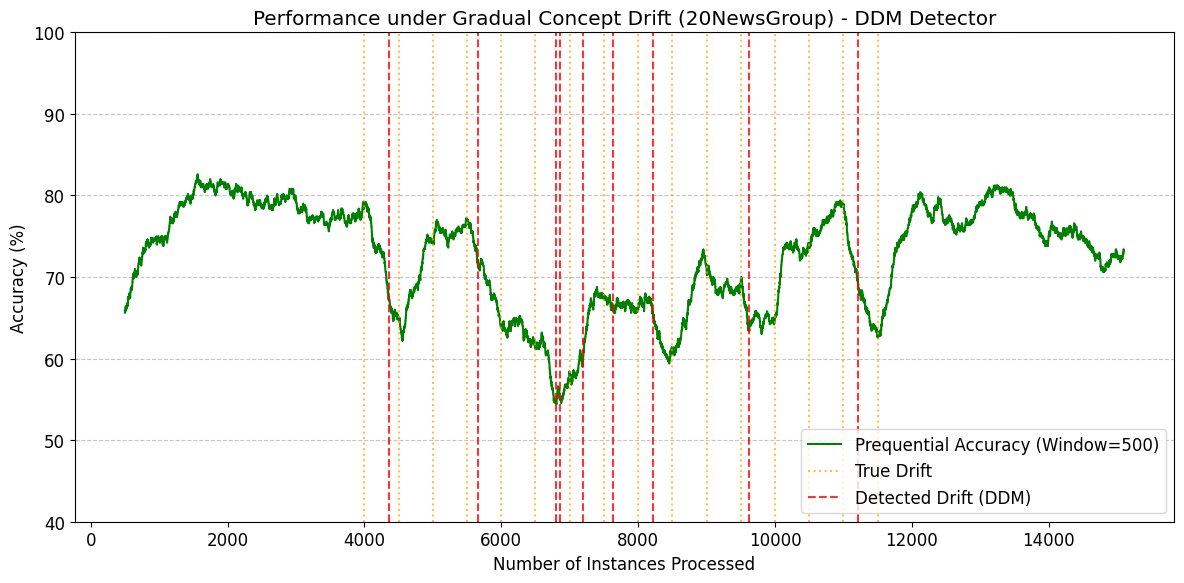

Total drifts detected by DDM: 9


In [24]:
file_path_gradual = '../data/adanen_streams/20ng_gradual.data'
detector_gradual = drift.binary.DDM()

acc_history_grad, drifts_grad = track_prequential_accuracy(file_path_gradual, detector_gradual)

plot_drift_result(acc_history_grad, drifts_grad,
                  'Performance under Gradual Concept Drift (20NewsGroup) - DDM Detector',
                  'green', '../images/20ng_gradual_drift.png')

### Results: Gradual Drift

- DDM detected 9 drifts, which is more than for abrupt drift (6).
- The first two detections (about 4350 and 5650) and the last two (about 9600 and 11200) are at the same places as in the abrupt stream.
- The main difference I noticed is between 6800 and 8250 instances. Here DDM detected 5 drifts in a short time, two of them almost at the same moment (around 6800).
- There are several true drifts in this part (around 7000, 7500 and 8000), so these detections can be reactions to real changes.
- In this part the accuracy stays at about 55-68%, which is lower than in the rest of the stream.
- The accuracy goes up to 80% again after 11500 instances and ends at about 73%.

## Final Conclusion

| Stream | Drifts detected (DDM) | Lowest accuracy | Final accuracy |
|--------|-----------------------|-----------------|----------------|
| Abrupt | 6 | ~55% | ~75% |
| Gradual | 9 | ~55% | ~73% |

- In both streams the accuracy is about 80% at the best moments and drops to 55-65% after drifts.
- The data has about 16 true drifts, but DDM detected only 6 and 9 of them, so it reacts only to a part of the changes.
- Every detection resets the model, so it loses everything it learned before. This is why the accuracy drops after each reset.
- In the next step I would compare DDM with the other detectors (ADWIN, EDDM, Page-Hinkley) and measure the detection delay.